<a href="https://colab.research.google.com/github/chandra-prakash-khudia/micrograd/blob/main/micrograd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [26]:
class Value:
  def __init__(self,data, _children=(), _ops='', label=''):
    self.data = data
    self._prev = set(_children)
    self._ops = _ops
    self.label = label
    self._backward = lambda: None
    self.grad = 0.0
  def __repr__(self):
    return f"Value (data ={self.data})"
  def __add__(self,other):
    other = other if isinstance(other, Value) else Value(other)
    out= Value(self.data + other.data, (self,other) , '+')
    def _backward():
      self.grad +=1.0 * out.grad
      other.grad += 1.0 *out.grad
    out._backward = _backward
    return out
  def __mul__(self,other):
    other = other if isinstance(other, Value) else Value(other)
    out =  Value(self.data * other.data , (self,other) , '*')
    def _backward():
      self.grad  += other.data * out.grad
      other.grad  += self.data * out.grad
    out._backward = _backward
    return out
  def __rmul__(self,other):
    return self * other
  def __truediv__(self,other):
    return self * other**-1
  def __neg__(self):
    return self * -1
  def __sub__(self,other):
    return self + (-other)
  def __radd__(self,other):
    return self + other
  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self,), 'tanh')
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    return out
  def __pow__(self,other):
    assert isinstance(other, (int,float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')
    def _backward():
      self.grad += other * self.data**(other-1) * out.grad
    out._backward = _backward
    return out
  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self,), 'exp')
    def _backward():
      self.grad += out.data * out.grad
    out._backward = _backward
    return out

  def backward(self):

    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

In [27]:
from graphviz import Digraph

def trace(root):
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child,v))
        build(child)
  build(root)
  return nodes, edges
def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label,n.data, n.grad), shape='record')
    if n._ops:
      dot.node(name = uid + n._ops, label = n._ops)
      dot.edge(uid + n._ops, uid)
      # for child in n._prev:
      # dot.edge(str(id(child)), str(id(n)))
  for n1, n2 in edges:
    dot.edge(str(id(n1)), str(id(n2)) + n2._ops)
  return dot

In [142]:
# Re-build the network utilizing the corrected class blueprint
x1 = Value(2.0, label='x1')
x2 = Value(1.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

# Initialize the top-level output gradient


In [148]:
o.backward()

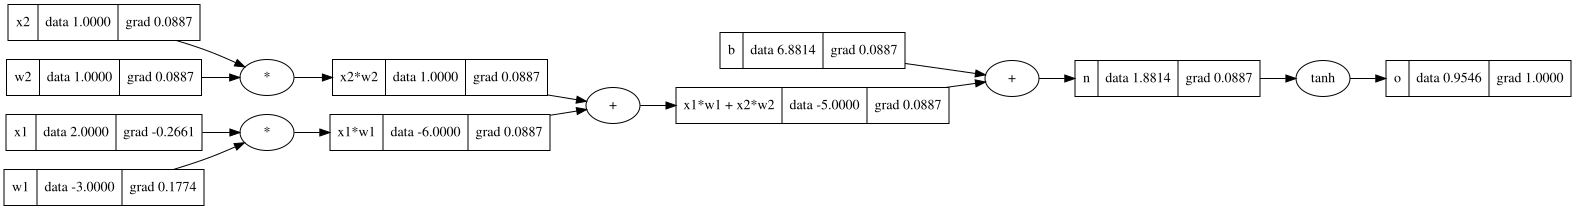

In [149]:
# Draw the updated computational graph with the new gradient values
draw_dot(o)

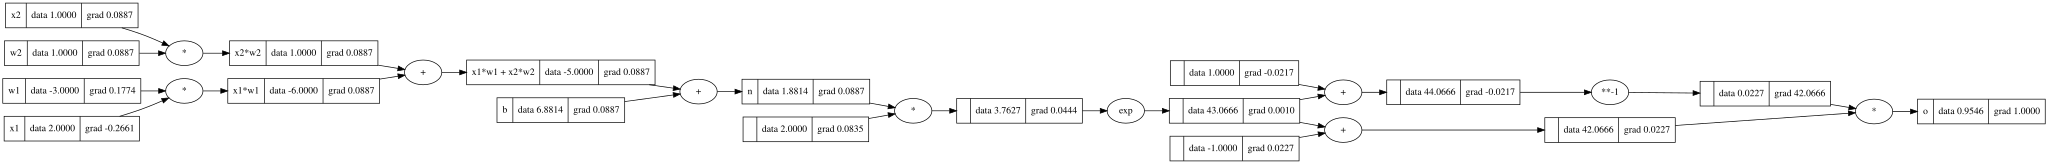

In [157]:
x1 = Value(2.0, label='x1')
x2 = Value(1.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
e = (2*n).exp()
o = (e-1)/(e +1)
o.label = 'o'
o.backward()
draw_dot(o)

In [1]:
import torch

In [83]:
x1 = torch.Tensor([2.0]).double() ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double() ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double() ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double() ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195]).double() ; b.requires_grad = True

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)
print(o.data.item())
o.backward()
print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [149]:
class Neuron:
  def __init__(self, nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))
  def __call__(self, x):
    # w * x + b
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    out = act.tanh()
    return out
  def parameters(self):
    return self.w + [self.b]

class Layer:
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]
  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs
  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]
    # params = []
    # for neuron in self.neurons:
    #   ps = neuron.parameters()
    #   params.extend(ps)
    # return params
class MLP:
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
  def __call__(self, x):
    for layer in self.layers:
        x = layer(x)
    return x
  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]


In [150]:
x = [2.0, 3.0,-1]
n = MLP(3,[4,4,1])
n(x)


Value (data =0.7439941902470986)

In [151]:
n.parameters()

[Value (data =-0.7736466896069973),
 Value (data =-0.3446967517798414),
 Value (data =0.671151000633909),
 Value (data =0.1287618785796958),
 Value (data =-0.5210652154893309),
 Value (data =0.24644520644953594),
 Value (data =-0.2524772794887995),
 Value (data =-0.13281453232499119),
 Value (data =0.8655545174859496),
 Value (data =0.2972842461553096),
 Value (data =0.14815598243738504),
 Value (data =0.6209390918732707),
 Value (data =0.3897321946764585),
 Value (data =0.048022386565161224),
 Value (data =0.16582620389150549),
 Value (data =-0.3101449865804651),
 Value (data =-0.898953841665018),
 Value (data =-0.5231453991519013),
 Value (data =-0.5555107548691745),
 Value (data =0.040120277025864404),
 Value (data =0.8574289365685146),
 Value (data =-0.06768957828890243),
 Value (data =0.9081776319040844),
 Value (data =-0.029408385110289537),
 Value (data =-0.811831206138512),
 Value (data =0.6712357032115817),
 Value (data =0.8704700505164829),
 Value (data =-0.5795992057584811),

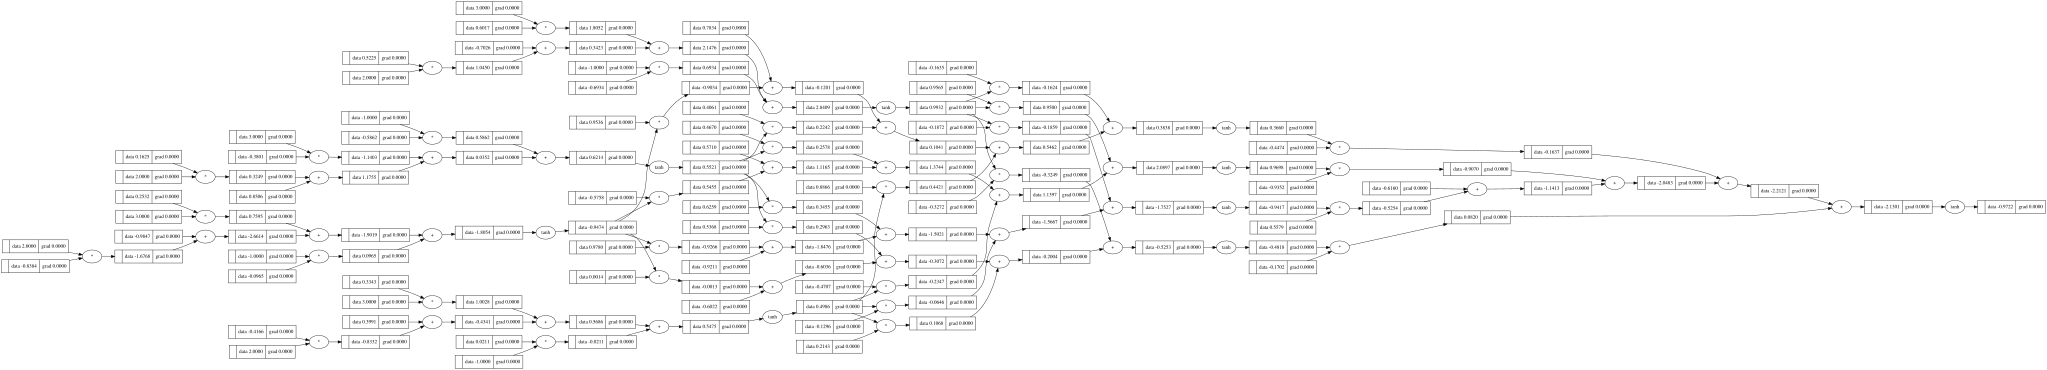

In [45]:
draw_dot(n(x))

In [152]:
xs = [
    [2.0, 3.0 , -1.0],
    [3.0 , -1.0, 0.5],
    [0.5 , 1.0 , 1.0],
    [1.0 , 1.0 , -1.0]
]
ys = [1.0 , -1.0 , -1.0, 1.0]


In [153]:
ypred = [n(x) for x in xs]
ypred

[Value (data =0.7439941902470986),
 Value (data =0.2969786174002232),
 Value (data =0.5351625829171393),
 Value (data =0.7846545477587241)]

In [154]:
loss = sum((yout-ygt)**2 for ygt, yout in zip(ys,ypred))
loss

Value (data =4.150790328410455)

In [155]:
loss.backward()

In [113]:
loss = sum((yout-ygt)**2 for ygt, yout in zip(ys,ypred))
loss

Value (data =6.935574016825127)

In [106]:
n.layers[0].neurons[0].w[0].grad

-92.49413046449428

In [107]:
n.layers[0].neurons[0].w[0]

Value (data =-0.29087203597124983)

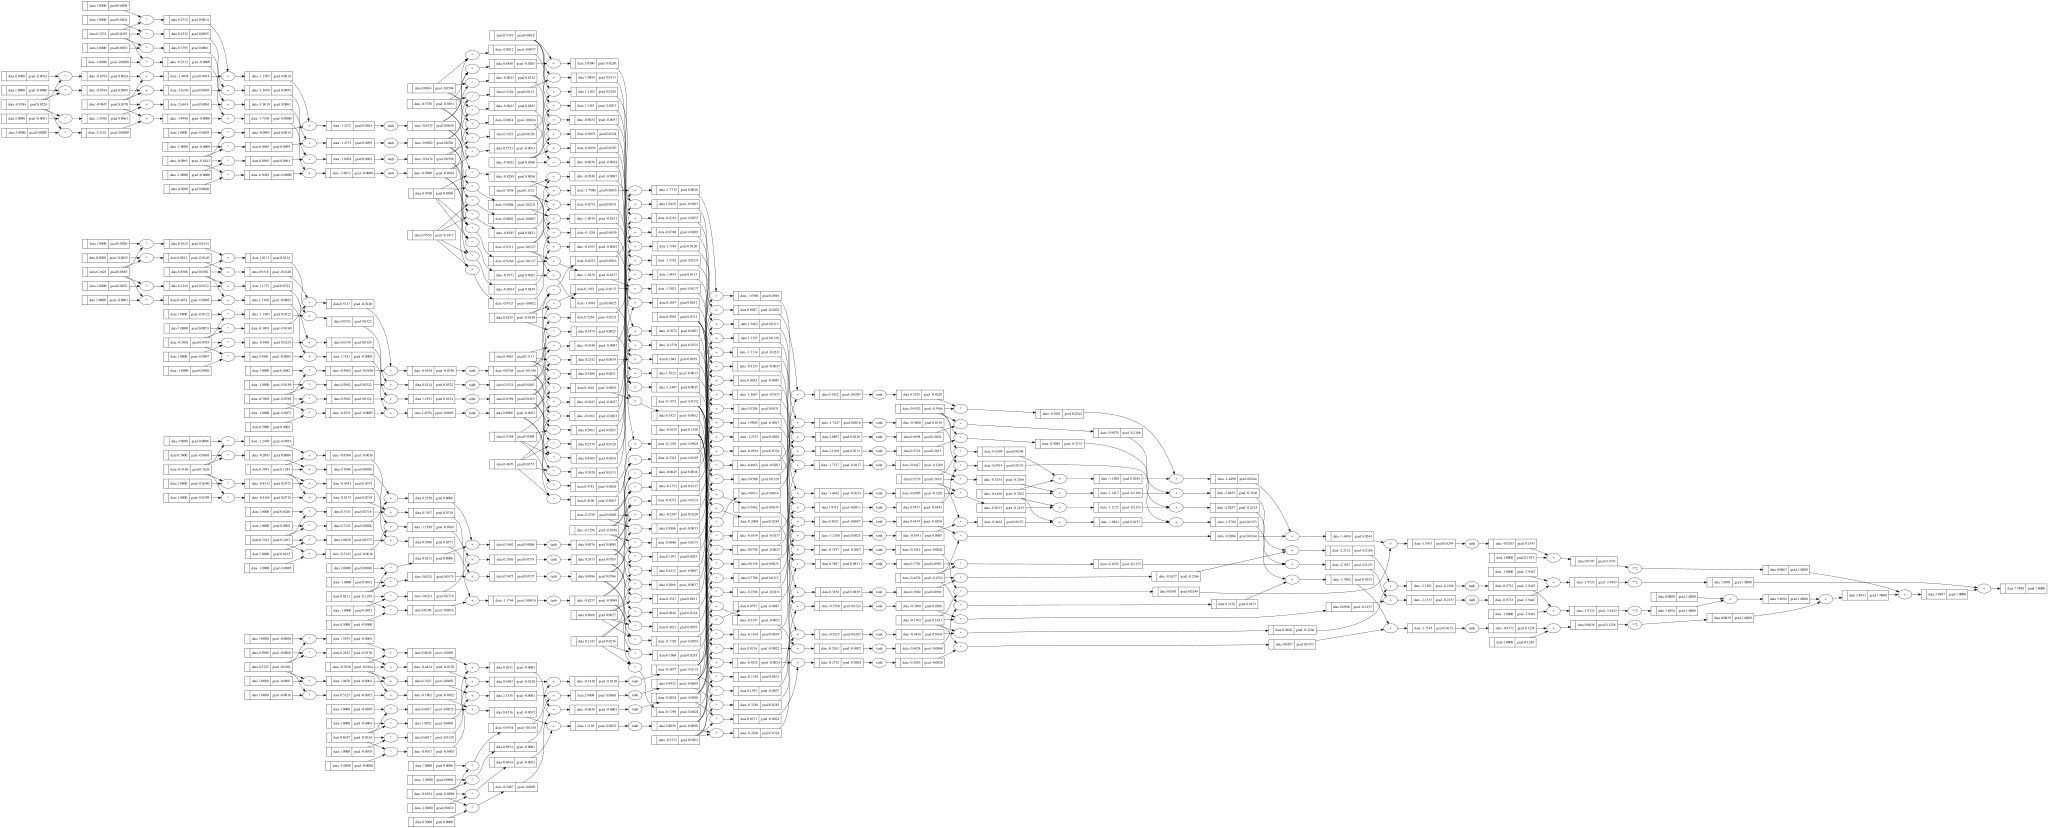

In [52]:
draw_dot(loss)

In [156]:
for p in n.parameters():
  p.data += -0.01 * p.grad


In [109]:

n.layers[0].neurons[0].w[0].data

0.6340692686736928

In [157]:
for k in range(10):
  # 1. Forward pass
  ypred = [n(x) for x in xs]
  loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

  # 2. Zero the gradients
  for p in n.parameters():
    p.grad = 0.0

  # 3. Backward pass
  loss.backward()

  # 4. Update parameters
  for p in n.parameters():
    p.data += -0.05 * p.grad

  print(k, f"{loss.data:.6f}")

0 3.361001
1 2.216530
2 2.203470
3 0.298461
4 0.209210
5 0.167552
6 0.139356
7 0.118643
8 0.102796
9 0.090326
